# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [57]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [58]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [59]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [60]:
numbers = list(range(10))

# Двічі ДО set_seed()
print("ДО set_seed (1):", random.randint(1, 100), random.sample(numbers, len(numbers)))
print("ДО set_seed (2):", random.randint(1, 100), random.sample(numbers, len(numbers)))

set_seed()
print("Seed зафіксовано:", SEED)

set_seed()
nums_1 = numbers.copy()
random.shuffle(nums_1)
res_1 = (random.randint(1, 100), nums_1)

set_seed()
nums_2 = numbers.copy()
random.shuffle(nums_2)
res_2 = (random.randint(1, 100), nums_2)

print("ПІСЛЯ set_seed (1):", res_1)
print("ПІСЛЯ set_seed (2):", res_2)

ДО set_seed (1): 4 [1, 3, 8, 4, 6, 0, 9, 2, 7, 5]
ДО set_seed (2): 58 [9, 4, 0, 6, 1, 3, 2, 5, 7, 8]
Seed зафіксовано: 42
ПІСЛЯ set_seed (1): (76, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
ПІСЛЯ set_seed (2): (76, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])


Генератори псевдовипадкових чисел детерміновані й відштовхуються від базового значення (seed). До виклику set_seed() стан генератора змінюється після кожної операції, тому результати різні. Коли ми викликаємо set_seed(42) перед кожною генерацією, ми щоразу скидаємо генератор у той самий початковий стан, тому значення randint та результат перемішування списку shuffle повторюються точнісінько один в один.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [61]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [62]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [63]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print("zeros_arr:\n", zeros_arr, "\nShape:", zeros_arr.shape, "Dtype:", zeros_arr.dtype)
print("\nsevens_arr:\n", sevens_arr, "\nShape:", sevens_arr.shape, "Dtype:", sevens_arr.dtype)


zeros_arr:
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] 
Shape: (3, 4) Dtype: float64

sevens_arr:
 [[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] 
Shape: (3, 4) Dtype: int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [64]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print("arange_arr:", arange_arr)
print("linspace_arr:", linspace_arr)


arange_arr: [ 0  2  4  6  8 10 12 14 16 18]
linspace_arr: [0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [65]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))


print("identity:\n", identity, "\nndim:", identity.ndim)
print("random_ints:\n", random_ints, "\nndim:", random_ints.ndim)

identity:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 
ndim: 2
random_ints:
 [[6 3 7]
 [4 6 9]
 [2 6 7]] 
ndim: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [66]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [67]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [68]:
df = pd.DataFrame({
    "student": ["Олена", "Андрій", "Максим", "Ірина", "Дмитро", "Катерина"],
    "score": [67, 69, 67, 74, 88, 91]
})

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)


    student  score
5  Катерина     91
4    Дмитро     88


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [69]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
conditions = [
    df["score"] >= 90,
    df["score"] >= 75
]
choices = ["A", "B"]
df["grade"] = np.select(conditions, choices, default="C")
print(df)


    student  score grade
0     Олена     67     C
1    Андрій     69     C
2    Максим     67     C
3     Ірина     74     C
4    Дмитро     88     B
5  Катерина     91     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [70]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print("zeros_t:\n", zeros_t, zeros_t.shape, zeros_t.dtype)
print("sevens_t:\n", sevens_t, sevens_t.shape, sevens_t.dtype)


zeros_t:
 tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
sevens_t:
 tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [71]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print("arange_t:", arange_t)
print("linspace_t:", linspace_t)


arange_t: tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
linspace_t: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [72]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)


print("from_list:\n", from_list, f"shape: {from_list.shape}, dtype: {from_list.dtype}, ndim: {from_list.ndim}")
print("random_t:\n", random_t, f"shape: {random_t.shape}, dtype: {random_t.dtype}, ndim: {random_t.ndim}")

from_list:
 tensor([[1, 2],
        [3, 4]]) shape: torch.Size([2, 2]), dtype: torch.int64, ndim: 2
random_t:
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) shape: torch.Size([3, 3]), dtype: torch.float32, ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [73]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Autograd grad:", x.grad.item())
print("Analytical grad (2 * n):", 2 * n)

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n


Autograd grad: 10.0
Analytical grad (2 * n): 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [74]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

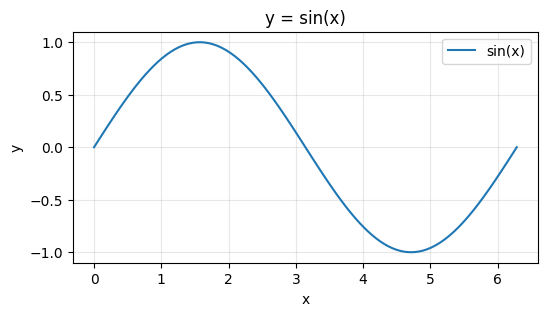

In [75]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.figure(figsize=(6, 3))
plt.plot(xs, np.sin(xs), label="sin(x)")
plt.title("y = sin(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

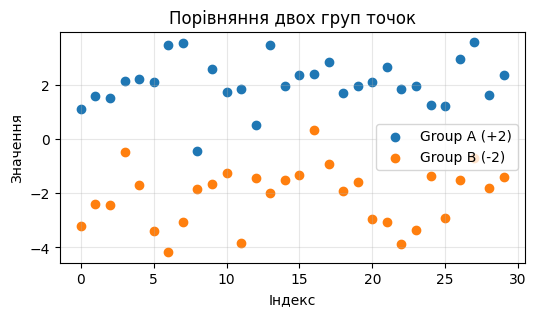

In [76]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.figure(figsize=(6, 3))
plt.scatter(range(len(group_a)), group_a, color="C0", label="Group A (+2)")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Group B (-2)")
plt.title("Порівняння двох груп точок")
plt.xlabel("Індекс")
plt.ylabel("Значення")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [77]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

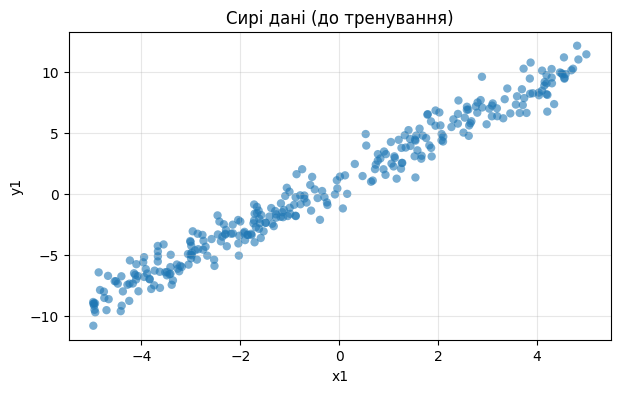

In [78]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"

plt.figure(figsize=(7, 4))
plt.scatter(x1.numpy(), y1.numpy(), alpha=0.6, edgecolors="none")
plt.title("Сирі дані (до тренування)")
plt.xlabel("x1")
plt.ylabel("y1")
plt.grid(True, alpha=0.3)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [79]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...

indices = torch.randperm(TASK1_N)
train_end = int(0.70 * TASK1_N)
val_end = int(0.85 * TASK1_N)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1, y_val1 = x1[val_idx], y1[val_idx]
x_test1, y_test1 = x1[test_idx], y1[test_idx]
print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [80]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


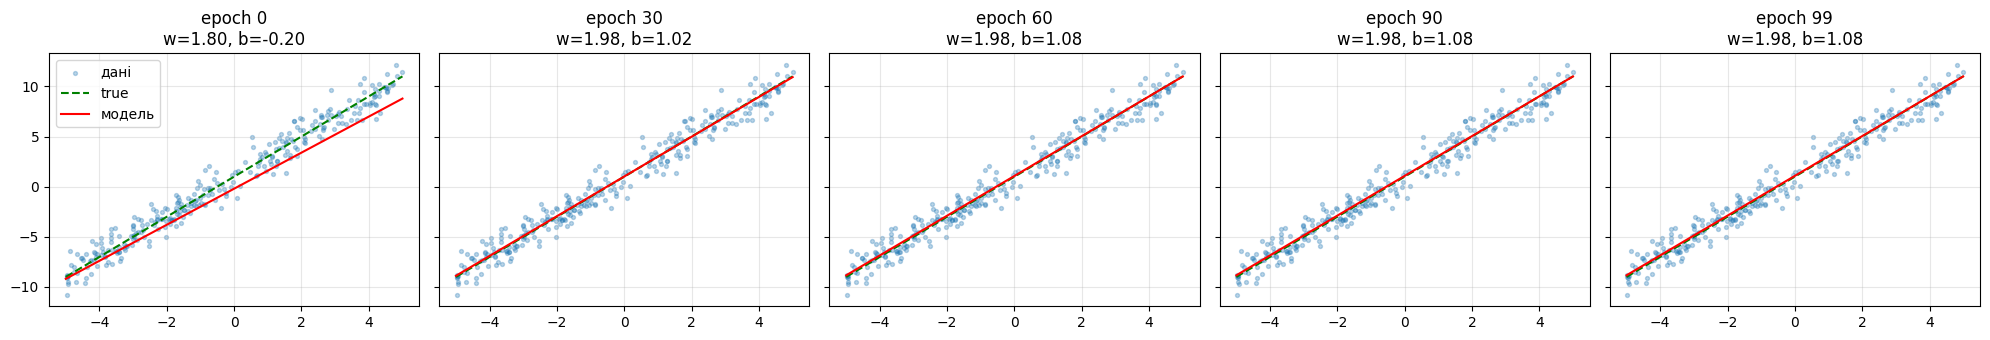

In [81]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Власний сценарій: Прогнозування річної вартості технічного обслуговування авто
* **Фіча ($x$):** Вік автомобіля у роках ($x \in [0, 15]$).
* **Цільова змінна ($y$):** Орієнтовні витрати на ТО та ремонт за рік (у сотнях євро, тобто 1 = 100€).
* **Параметри моделі:**
  * $b = 2.0$ (200€) — базове регулярне річне ТО (мастило, фільтри) для нового автомобіля.
  * $w = 1.2$ (120€/рік) — середня швидкість росту витрат на знос вузлів (гальма, підвіска, ремені) з кожним наступним роком експлуатації.
  * $\varepsilon \sim \mathcal{N}(0, 1.5^2)$ — шум (непередбачувані випадкові несправності або різний пробіг).

In [82]:
def generate_linear_data(w: float, b: float, n_samples: int = 400, noise_std: float = 1.5):
    x = torch.empty(n_samples, 1).uniform_(0, 15)
    noise = noise_std * torch.randn(n_samples, 1)
    y = w * x + b + noise
    return x, y

def split_data(x: torch.Tensor, y: torch.Tensor, train_ratio=0.7, val_ratio=0.15):
    n = len(x)
    indices = torch.randperm(n)
    train_end = int(train_ratio * n)
    val_end = int((train_ratio + val_ratio) * n)

    return (
        x[indices[:train_end]], y[indices[:train_end]],
        x[indices[train_end:val_end]], y[indices[train_end:val_end]],
        x[indices[val_end:]], y[indices[val_end:]]
    )

def train_linear_model(x_train, y_train, x_val, y_val, lr=0.01, epochs=150):
    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(x_train), y_train)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val).item()
    return model, val_loss

def evaluate_model(model, x_test, y_test):
    model.eval()
    loss_fn = torch.nn.MSELoss()
    with torch.no_grad():
        preds = model(x_test)
        test_loss = loss_fn(preds, y_test).item()
    return test_loss

# Генерація та збереження в CSV
TRUE_W_CUSTOM = 1.2
TRUE_B_CUSTOM = 2.0
x_custom, y_custom = generate_linear_data(TRUE_W_CUSTOM, TRUE_B_CUSTOM)

dataset_df = pd.DataFrame({
    "car_age_years": x_custom.squeeze().numpy(),
    "annual_maintenance_cost_x100eur": y_custom.squeeze().numpy()
})

# Збереження локально та на Drive
dataset_df.to_csv("dataset.csv", index=False)
if os.path.exists(ARTIFACT_DIR):
    dataset_df.to_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"), index=False)

# Спліт, навчання та тестування
xtr, ytr, xv, yv, xte, yte = split_data(x_custom, y_custom)
custom_model, val_loss = train_linear_model(xtr, ytr, xv, yv)
test_loss = evaluate_model(custom_model, xte, yte)

print(f"Оцінені параметри: w = {custom_model.weight.item():.4f}, b = {custom_model.bias.item():.4f}")
print(f"Val MSE: {val_loss:.4f} | Test MSE: {test_loss:.4f}")

Оцінені параметри: w = 1.2402, b = 1.5242
Val MSE: 2.6198 | Test MSE: 1.6965


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [83]:
torch.save(custom_model.state_dict(), "model.pt")
torch.save(custom_model.state_dict(), f"{ARTIFACT_DIR}/model.pt")
print(f"Модель збережено локально та на Drive в {ARTIFACT_DIR}/model.pt")

Модель збережено локально та на Drive в /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [84]:
!pip install -q gradio
import gradio as gr

inference_model = torch.nn.Linear(1, 1)
inference_model.load_state_dict(torch.load("model.pt"))
inference_model.eval()

# Функція передбачення для інтерфейсу
def predict_cost(car_age):
    input_tensor = torch.tensor([[float(car_age)]], dtype=torch.float32)
    with torch.no_grad():
        pred_val = inference_model(input_tensor).item()
    total_eur = max(0.0, pred_val * 100.0)
    return f"Орієнтовні витрати на рік: {total_eur:.2f} €"

# Запуск веб-інтерфейсу
demo = gr.Interface(
    fn=predict_cost,
    inputs=gr.Slider(minimum=0.0, maximum=15.0, step=0.5, value=3.0, label="Вік авто (років)"),
    outputs=gr.Textbox(label="Прогноз витрат"),
    title="Калькулятор ТО автомобіля"
)
demo.launch(inline=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://db201623a5cc6e70bc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```